<a href="https://colab.research.google.com/github/anujjakhotiya/AI-DL_2026/blob/main/Lab_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub

import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn

from collections import Counter
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix
)

import kagglehub

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [2]:
# Download dataset from Kaggle
dataset_path = kagglehub.dataset_download(
    "yufengdev/bbc-fulltext-and-category"
)

print("Dataset downloaded to:", dataset_path)

# Find CSV file
csv_file = None

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_file = os.path.join(root, file)
            break
    if csv_file:
        break

if csv_file is None:
    raise FileNotFoundError("CSV file not found in dataset folder.")

df = pd.read_csv(csv_file)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Using Colab cache for faster access to the 'bbc-fulltext-and-category' dataset.
Dataset downloaded to: /kaggle/input/bbc-fulltext-and-category
Dataset shape: (2225, 2)
Columns: ['category', 'text']
        category                                               text
0           tech  tv future in the hands of viewers with home th...
1       business  worldcom boss  left books alone  former worldc...
2          sport  tigers wary of farrell  gamble  leicester say ...
3          sport  yeading face newcastle in fa cup premiership s...
4  entertainment  ocean s twelve raids box office ocean s twelve...


Total articles: 2126
Categories: ['business', 'entertainment', 'politics', 'sport', 'tech']

Category distribution:
category
sport            504
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64


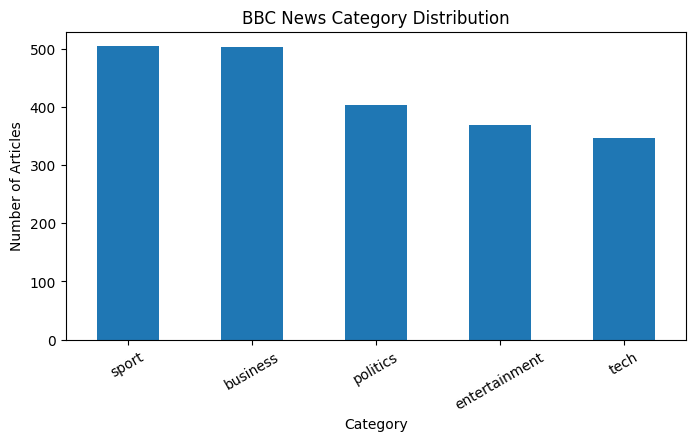

In [3]:
# Identify text and category columns
text_col = next(
    (c for c in df.columns if c.lower() in ["text", "article", "content"]),
    None
)

label_col = next(
    (c for c in df.columns if c.lower() in ["category", "label"]),
    None
)

if text_col is None or label_col is None:
    raise ValueError("Could not identify text and category columns.")

# Remove missing values and duplicates
df = df[[text_col, label_col]].dropna()
df = df.drop_duplicates()

# Convert text to lowercase and remove unwanted characters
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["text"] = df[text_col].apply(clean_text)
df["category"] = df[label_col].astype(str).str.lower().str.strip()

# Remove empty articles
df = df[df["text"].str.len() > 0].reset_index(drop=True)

# Encode categories
categories = sorted(df["category"].unique())
label_to_id = {label: i for i, label in enumerate(categories)}
id_to_label = {i: label for label, i in label_to_id.items()}

df["label"] = df["category"].map(label_to_id)

print("Total articles:", len(df))
print("Categories:", categories)
print("\nCategory distribution:")
print(df["category"].value_counts())

# Visualize category distribution
df["category"].value_counts().plot(
    kind="bar", figsize=(8, 4), title="BBC News Category Distribution"
)
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=30)
plt.show()

In [4]:
X = df["text"].values
y = df["label"].values

# 70% training, 15% validation, 15% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 1488
Validation samples: 319
Testing samples: 319


In [5]:
MAX_VOCAB = 15000
MAX_LEN = 256

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

def tokenize(text):
    return text.split()

# Build vocabulary using only training data
counter = Counter()

for text in X_train:
    counter.update(tokenize(text))

vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word, count in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))

def encode_text(text):
    tokens = tokenize(text)
    ids = [vocab.get(word, vocab[UNK_TOKEN]) for word in tokens]

    ids = ids[:MAX_LEN]

    # Padding
    ids += [vocab[PAD_TOKEN]] * (MAX_LEN - len(ids))

    return ids

Vocabulary size: 15000


In [6]:
class NewsDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        input_ids = encode_text(self.texts[index])

        return (
            torch.tensor(input_ids, dtype=torch.long),
            torch.tensor(self.labels[index], dtype=torch.long)
        )

BATCH_SIZE = 32

train_dataset = NewsDataset(X_train, y_train)
val_dataset = NewsDataset(X_val, y_val)
test_dataset = NewsDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [7]:
class TransformerClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        num_classes,
        embed_dim=128,
        num_heads=4,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=0
        )

        self.position_embedding = nn.Embedding(
            MAX_LEN, embed_dim
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=256,
            dropout=dropout,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(embed_dim, num_classes)

    def forward(self, input_ids):

        batch_size, seq_length = input_ids.shape

        positions = torch.arange(
            seq_length, device=input_ids.device
        ).unsqueeze(0).expand(batch_size, seq_length)

        x = self.embedding(input_ids)
        x = x + self.position_embedding(positions)

        # Mask padding tokens
        padding_mask = input_ids == 0

        x = self.transformer(
            x,
            src_key_padding_mask=padding_mask
        )

        # Mean pooling over non-padding tokens
        valid_tokens = (~padding_mask).unsqueeze(-1)

        x = x * valid_tokens

        pooled = x.sum(dim=1) / valid_tokens.sum(
            dim=1
        ).clamp(min=1)

        output = self.fc(self.dropout(pooled))

        return output


model = TransformerClassifier(
    vocab_size=len(vocab),
    num_classes=len(categories)
).to(device)

print(model)

TransformerClassifier(
  (embedding): Embedding(15000, 128, padding_idx=0)
  (position_embedding): Embedding(256, 128)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=5, bias=True)
)


In [9]:
EPOCHS = 3
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(EPOCHS):

    # Training
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(train_loader)
    train_acc = correct / total

    # Validation
    model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for inputs, labels in val_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= len(val_loader)
    val_acc = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Accuracy: {train_acc*100:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Accuracy: {val_acc*100:.2f}%"
    )

Epoch [1/3] Train Loss: 0.1217 Train Accuracy: 96.77% Val Loss: 0.3918 Val Accuracy: 86.21%
Epoch [2/3] Train Loss: 0.0502 Train Accuracy: 98.39% Val Loss: 0.2811 Val Accuracy: 93.10%
Epoch [3/3] Train Loss: 0.0304 Train Accuracy: 98.99% Val Loss: 0.3866 Val Accuracy: 89.03%


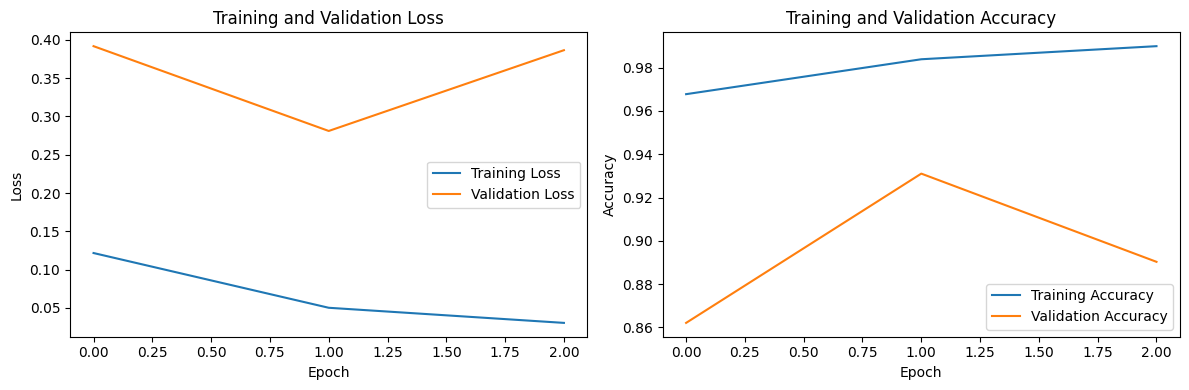

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

Transformer Test Accuracy: 87.77%

Classification Report:

               precision    recall  f1-score   support

     business       0.90      0.92      0.91        76
entertainment       0.76      0.91      0.83        55
     politics       0.91      0.80      0.85        61
        sport       0.95      0.96      0.95        75
         tech       0.87      0.75      0.80        52

     accuracy                           0.88       319
    macro avg       0.88      0.87      0.87       319
 weighted avg       0.88      0.88      0.88       319



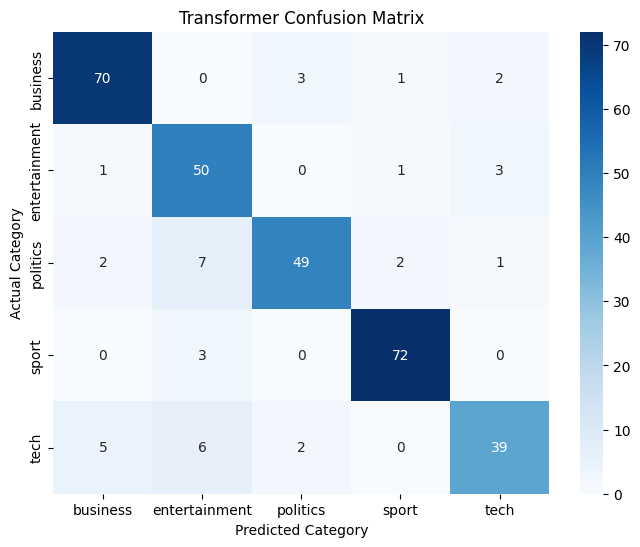

In [11]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for inputs, labels in test_loader:

        inputs = inputs.to(device)

        outputs = model(inputs)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(labels.numpy())

transformer_accuracy = accuracy_score(
    all_labels, all_predictions
)

print("Transformer Test Accuracy:",
      f"{transformer_accuracy * 100:.2f}%")

print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    target_names=categories,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=categories,
    yticklabels=categories
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Transformer Confusion Matrix")
plt.show()

In [12]:
# Convert text into TF-IDF features
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Train baseline model
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

baseline_model.fit(X_train_tfidf, y_train)

# Predict
baseline_predictions = baseline_model.predict(
    X_test_tfidf
)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

print("Baseline Test Accuracy:",
      f"{baseline_accuracy * 100:.2f}%")

print("\nBaseline Classification Report:\n")

print(classification_report(
    y_test,
    baseline_predictions,
    target_names=categories,
    zero_division=0
))

Baseline Test Accuracy: 97.18%

Baseline Classification Report:

               precision    recall  f1-score   support

     business       0.94      0.97      0.95        76
entertainment       0.98      0.95      0.96        55
     politics       0.98      0.98      0.98        61
        sport       1.00      1.00      1.00        75
         tech       0.96      0.94      0.95        52

     accuracy                           0.97       319
    macro avg       0.97      0.97      0.97       319
 weighted avg       0.97      0.97      0.97       319



                          Model  Test Accuracy
0           Transformer Encoder      87.774295
1  TF-IDF + Logistic Regression      97.178683


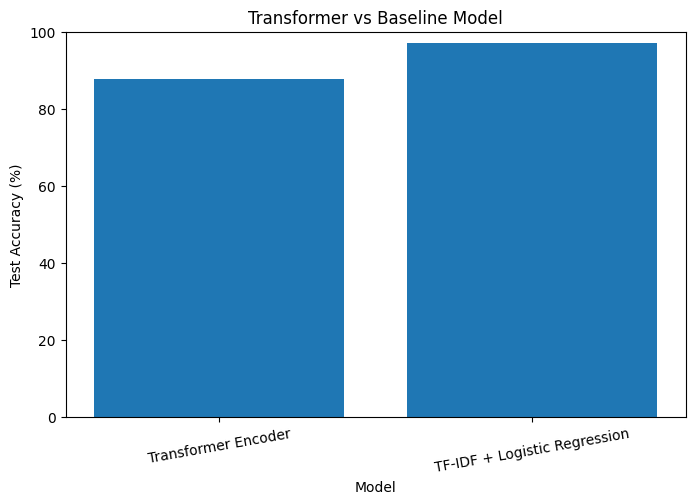

In [13]:
comparison = pd.DataFrame({
    "Model": [
        "Transformer Encoder",
        "TF-IDF + Logistic Regression"
    ],
    "Test Accuracy": [
        transformer_accuracy * 100,
        baseline_accuracy * 100
    ]
})

print(comparison)

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Test Accuracy"]
)

plt.title("Transformer vs Baseline Model")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=10)

plt.show()

In [14]:
# Display predictions for five test articles
print("Sample News Predictions:\n")

for i in range(min(5, len(X_test))):

    actual = id_to_label[int(y_test[i])]

    predicted = id_to_label[
        int(all_predictions[i])
    ]

    print("Article:", X_test[i][:180], "...")
    print("Actual Category:", actual)
    print("Predicted Category:", predicted)
    print("-" * 60)

Sample News Predictions:

Article: hewitt falls to dent in adelaide lleyton hewitt suffered a shock defeat to taylor dent in the quarter finals of the australian hardcourt championships in adelaide on friday the top ...
Actual Category: sport
Predicted Category: sport
------------------------------------------------------------
Article: brizzel to run aaa s in sheffield ballymena sprinter paul brizzel will be among eight of ireland s european indoor hopefuls competing in this weekend s aaa s championships us based ...
Actual Category: sport
Predicted Category: sport
------------------------------------------------------------
Article: sayeed to stand down as tory mp tory mp jonathan sayeed is to stand down on the grounds of ill health the decision comes after mr sayeed survived an attempt to de select him in a r ...
Actual Category: politics
Predicted Category: politics
------------------------------------------------------------
Article: women mps reveal sexist taunts women mps endure

In [15]:
torch.save({
    "model_state_dict": model.state_dict(),
    "vocab": vocab,
    "categories": categories,
    "max_len": MAX_LEN
}, "bbc_transformer_model.pth")

print("Model saved successfully!")

Model saved successfully!
